In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

# Load dataset
df = pd.read_csv(r"C:\Users\princ\Downloads\predictive_maintenance.csv")
df.head()


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [10]:
# Drop unnecessary columns
df.drop(['UDI', 'Product ID'], axis=1, inplace=True)

# Check for missing values
print(df.isnull().sum())

# Confirm datatypes
print(df.dtypes)

# Check unique values in target
print(df['Machine failure'].value_counts())

Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64
Type                        object
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64
dtype: object
Machine failure
0    9661
1     339
Name: count, dtype: int64


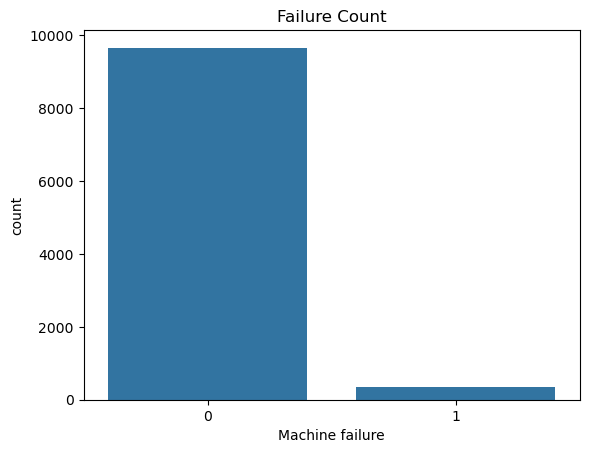

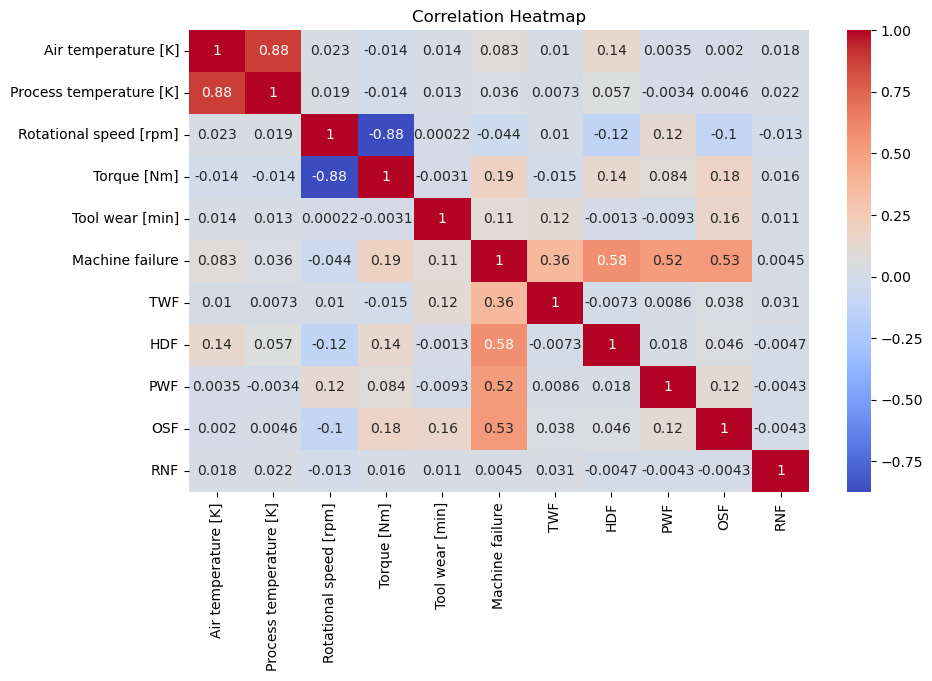

In [13]:
# Plot failure distribution
sns.countplot(data=df, x='Machine failure')
plt.title("Failure Count")
plt.show()

# Correlation Heatmap
plt.figure(figsize=(10, 6))

# Keep only numeric columns for correlation
numeric_df = df.select_dtypes(include=['number'])

sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()


In [24]:
# 1. Encode the 'Type' column
df_encoded = df.copy()
df_encoded['Type'] = df_encoded['Type'].map({'L': 0, 'M': 1, 'H': 2})  # L=Low, M=Medium, H=High

# 2. Define features and target
X = df_encoded.drop('Machine failure', axis=1)
y = df_encoded['Machine failure']

# 3. Split the dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Print shape of splits
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (8000, 11)
X_test shape: (2000, 11)
y_train shape: (8000,)
y_test shape: (2000,)


In [26]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Initialize the model
model = RandomForestClassifier(random_state=42)

# 2. Train the model
model.fit(X_train, y_train)

# 3. Predict on test data
y_pred = model.predict(X_test)

# 4. Evaluate the model
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))

Accuracy: 0.999

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00      1939
           1       1.00      0.97      0.98        61

    accuracy                           1.00      2000
   macro avg       1.00      0.98      0.99      2000
weighted avg       1.00      1.00      1.00      2000


Confusion Matrix:
 [[1939    0]
 [   2   59]]


In [27]:
import joblib
import pandas as pd

# 1. Save the trained model
joblib.dump(model, 'machine_failure_model.pkl')

# 2. Save predictions alongside actual values
results_df = X_test.copy()
results_df['Actual'] = y_test.values
results_df['Predicted'] = y_pred

# 3. Save the results to a CSV file
results_df.to_csv('prediction_results.csv', index=False)

print("Model and prediction results saved successfully!")

Model and prediction results saved successfully!
